# NYC 311 Customer Service Requests Analysis
## Course-End Project 1 – Python for Data Science

---

### Project Objectives
1. **Understand the Dataset**: Identify the shape, column types, and variables containing missing values.
2. **Data Wrangling & Cleaning**:
   - Handle missing values in categorical and numerical columns.
   - Parse timestamps and eliminate records with invalid chronological timelines (e.g., closed before created).
   - Engineer time features (Year, Month, Day, Day of Week).
3. **Exploratory Data Analysis (EDA)**:
   - Identify city-wise complaint frequencies and plot top cities.
   - Visualize geographical concentration and density of complaints in Brooklyn using scatter and hexbin plots.
4. **Complaint Type Analysis**:
   - Determine major and top 10 complaint categories across New York City.
   - Construct a dedicated dataset showing complaint distributions by city.
   - Visualize major complaint types across different cities via heatmaps.
5. **Response Time Analysis**:
   - Calculate resolution times in hours (`Closed Date` - `Created Date`).
   - Identify average and median response times across different complaint types.
6. **Statistical Hypothesis Testing**:
   - Perform a Chi-Square test of independence to assess if complaint types are statistically associated with specific boroughs.


## 1. Import Required Libraries and Configure Environment

In [1]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency

# Configure visualization settings
warnings.filterwarnings('ignore')
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.sans-serif'] = 'Helvetica', 'DejaVu Sans', 'Arial'

# Create output directories if they don't exist
os.makedirs('../output', exist_ok=True)
os.makedirs('../visualizations', exist_ok=True)

print("Libraries imported and configuration complete.")


Libraries imported and configuration complete.


## 2. Load the Dataset
We load the raw CSV file `311_Service_Requests_from_2010_to_Present.csv` located in the `../data/` directory with `low_memory=False` to handle mixed dtypes.

In [2]:
data_path = os.path.join('..', 'data', '311_Service_Requests_from_2010_to_Present.csv')
if not os.path.exists(data_path):
    data_path = '311_Service_Requests_from_2010_to_Present.csv'

df = pd.read_csv(data_path, low_memory=False)
print("Dataset successfully loaded. Number of records:", len(df))


Dataset successfully loaded. Number of records: 300698


## 3. Understand the Dataset

### 3.1 Dataset Shape and Dimensions

In [3]:
print(f"Number of rows    : {df.shape[0]:,}")
print(f"Number of columns : {df.shape[1]}")
print(f"Dataset Dimensions: {df.shape}")


Number of rows    : 300,698
Number of columns : 53
Dataset Dimensions: (300698, 53)


### 3.2 Preview First Five Records

In [4]:
df.head()

,Unique Key,Created Date,Closed Date,Agency,Agency Name,Complaint Type,Descriptor,Location Type,Incident Zip,Incident Address,...,Bridge Highway Name,Bridge Highway Direction,Road Ramp,Bridge Highway Segment,Garage Lot Name,Ferry Direction,Ferry Terminal Name,Latitude,Longitude,Location
0,32310363,12/31/2015 11:59:45 PM,01-01-16 0:55,NYPD,New York City Police Department,Noise - Street/Sidewalk,Loud Music/Party,Street/Sidewalk,10034.0,71 VERMILYEA AVENUE,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,40.865682,-73.923501,"(40.86568153633767, -73.92350095571744)"
1,32309934,12/31/2015 11:59:44 PM,01-01-16 1:26,NYPD,New York City Police Department,Blocked Driveway,No Access,Street/Sidewalk,11105.0,27-07 23 AVENUE,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,40.775945,-73.915094,"(40.775945312321085, -73.91509393898605)"
2,32309159,12/31/2015 11:59:29 PM,01-01-16 4:51,NYPD,New York City Police Department,Blocked Driveway,No Access,Street/Sidewalk,10458.0,2897 VALENTINE AVENUE,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,40.870325,-73.888525,"(40.870324522111424, -73.88852464418646)"
3,32305098,12/31/2015 11:57:46 PM,01-01-16 7:43,NYPD,New York City Police Department,Illegal Parking,Commercial Overnight Parking,Street/Sidewalk,10461.0,2940 BAISLEY AVENUE,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,40.835994,-73.828379,"(40.83599404683083, -73.82837939584206)"
4,32306529,12/31/2015 11:56:58 PM,01-01-16 3:24,NYPD,New York City Police Department,Illegal Parking,Blocked Sidewalk,Street/Sidewalk,11373.0,87-14 57 ROAD,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,40.733060,-73.874170,"(40.733059618956815, -73.87416975810375)"


### 3.3 Identify Variables with Null Values

In [5]:
missing_values = df.isnull().sum()
missing_pct = (missing_values / len(df)) * 100

missing_df = pd.DataFrame({
    'Column': missing_values.index,
    'Missing Values': missing_values.values,
    'Missing Percentage (%)': missing_pct.values
}).sort_values(by='Missing Percentage (%)', ascending=False).reset_index(drop=True)

print(f"Total columns with missing values: {(missing_values > 0).sum()} / {df.shape[1]}")
missing_df.head(20)


Total columns with missing values: 35 / 53


,Column,Missing Values,Missing Percentage (%)
0,School or Citywide Complaint,300698,100.000000
1,Vehicle Type,300698,100.000000
2,Taxi Company Borough,300698,100.000000
3,Taxi Pick Up Location,300698,100.000000
4,Garage Lot Name,300698,100.000000
5,Ferry Direction,300697,99.999667
6,Ferry Terminal Name,300696,99.999335
7,Road Ramp,300485,99.929165
8,Bridge Highway Segment,300485,99.929165
9,Bridge Highway Name,300455,99.919188


### 3.4 Visualize Missing Values Across Selected Columns

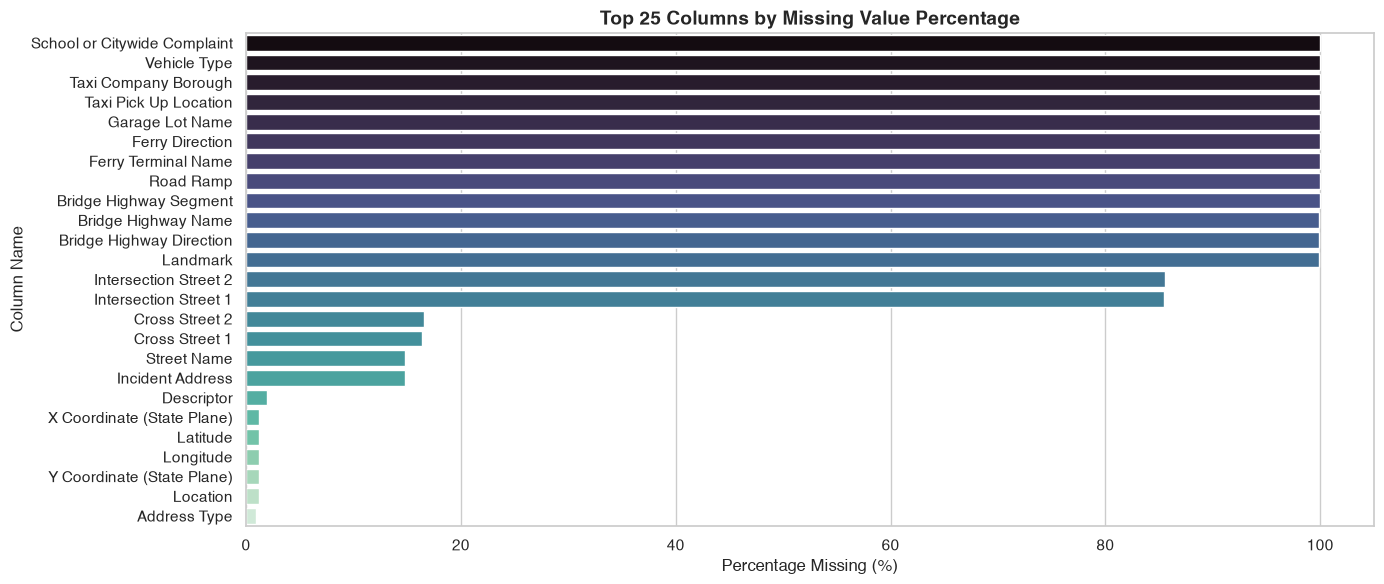

In [6]:
plt.figure(figsize=(14, 6))
top_missing_cols = missing_df[missing_df['Missing Values'] > 0].head(25)
sns.barplot(data=top_missing_cols, x='Missing Percentage (%)', y='Column', palette='mako')
plt.title("Top 25 Columns by Missing Value Percentage", fontsize=14, fontweight='bold')
plt.xlabel("Percentage Missing (%)")
plt.ylabel("Column Name")
plt.tight_layout()
plt.show()


## 4. Data Cleaning & Missing Value Treatment

### 4.1 Check for Duplicate Records

In [7]:
duplicates = df.duplicated().sum()
print("Number of duplicate rows:", duplicates)
if duplicates > 0:
    df = df.drop_duplicates()


Number of duplicate rows: 0


### 4.2 Impute Missing Categorical Values and Standardize Formatting
For key categorical columns (`Complaint Type`, `City`, `Borough`), missing values are imputed with `'Unknown'` and text casing is standardized.

In [8]:
df['Complaint Type'] = df['Complaint Type'].fillna('Unknown').str.strip()
df['City'] = df['City'].fillna('Unknown').str.strip().str.title()
df['Borough'] = df['Borough'].fillna('Unknown').str.strip().str.title()

# Numeric coercion for geographic coordinates
df['Latitude'] = pd.to_numeric(df['Latitude'], errors='coerce')
df['Longitude'] = pd.to_numeric(df['Longitude'], errors='coerce')

print("Missing values in core categorical attributes after imputation:")
print(df[['Complaint Type', 'City', 'Borough']].isnull().sum())


Missing values in core categorical attributes after imputation:
Complaint Type    0
City              0
Borough           0
dtype: int64


## 5. Analyze Date Columns & Remove Invalid Timelines

Convert date strings to pandas `datetime` format and eliminate anomalies:
- Missing `Created Date` entries.
- Inconsistent timelines where `Closed Date` occurs before `Created Date`.

In [9]:
# Parse datetime
df['Created Date'] = pd.to_datetime(df['Created Date'], errors='coerce')
df['Closed Date'] = pd.to_datetime(df['Closed Date'], errors='coerce')

print("Invalid / Missing Created Dates:", df['Created Date'].isnull().sum())
print("Invalid / Missing Closed Dates :", df['Closed Date'].isnull().sum())

# Drop records with invalid Created Date
df = df.dropna(subset=['Created Date'])

# Validate chronology: Closed Date must be >= Created Date (or null for ongoing cases)
invalid_timeline_mask = (df['Closed Date'].notnull()) & (df['Closed Date'] < df['Created Date'])
print(f"Records with invalid timeline (Closed Date < Created Date): {invalid_timeline_mask.sum()}")

df = df[~invalid_timeline_mask]
print("Dataset shape after date filtering:", df.shape)


Invalid / Missing Created Dates: 0
Invalid / Missing Closed Dates : 2164
Records with invalid timeline (Closed Date < Created Date): 0
Dataset shape after date filtering: (300698, 53)


### 5.1 Date Feature Engineering & Temporal Trends

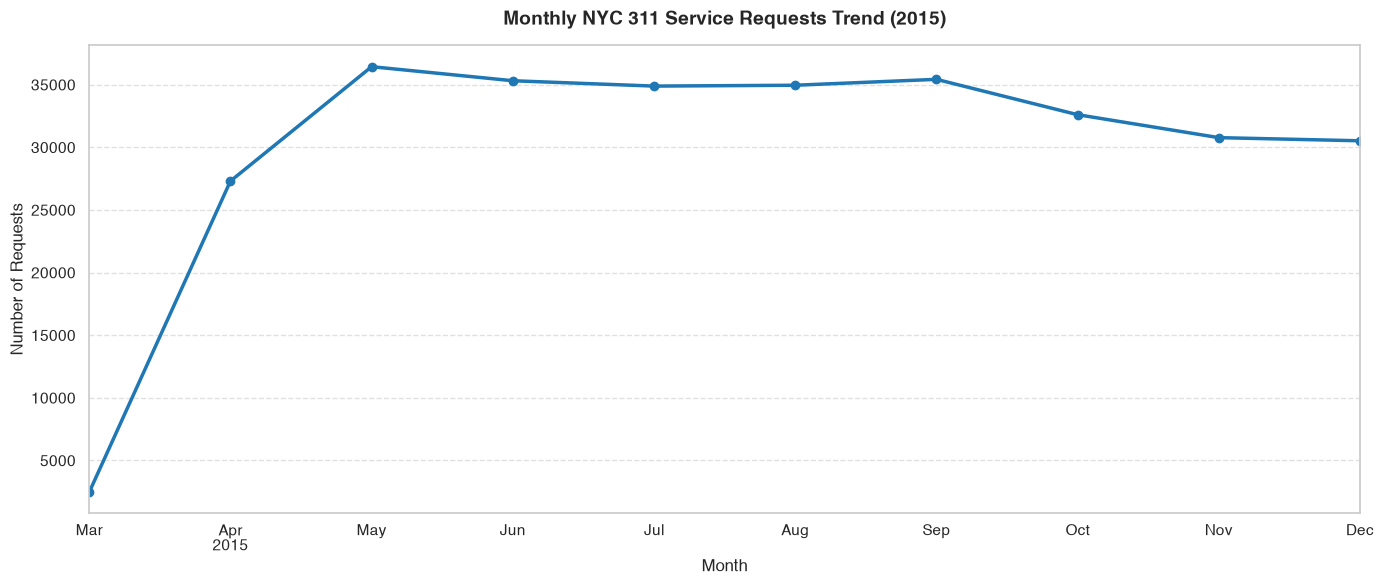

In [10]:
df['Year'] = df['Created Date'].dt.year
df['Month'] = df['Created Date'].dt.month
df['Day'] = df['Created Date'].dt.day
df['Day_Name'] = df['Created Date'].dt.day_name()
df['Year_Month'] = df['Created Date'].dt.to_period('M')

monthly_trend = df.groupby('Year_Month').size()

plt.figure(figsize=(14, 6))
monthly_trend.plot(kind='line', marker='o', color='#1f77b4', linewidth=2.5, markersize=6)
plt.title("Monthly NYC 311 Service Requests Trend (2015)", fontsize=14, fontweight='bold', pad=15)
plt.xlabel("Month", fontsize=12)
plt.ylabel("Number of Requests", fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.savefig('../visualizations/monthly_complaints.png', dpi=300)
plt.show()


## 6. Frequency Plot for City-Wise Complaints
Assess the geographic distribution of complaints across NYC cities/boroughs.

Top 15 Cities by Service Request Volume:
City
Brooklyn               98307
New York               65994
Bronx                  40702
Staten Island          12343
Jamaica                 7296
Astoria                 7047
Flushing                5971
Ridgewood               5163
Corona                  4295
Woodside                3664
South Richmond Hill     2774
Ozone Park              2755
East Elmhurst           2748
Elmhurst                2673
Unknown                 2614
Name: count, dtype: int64


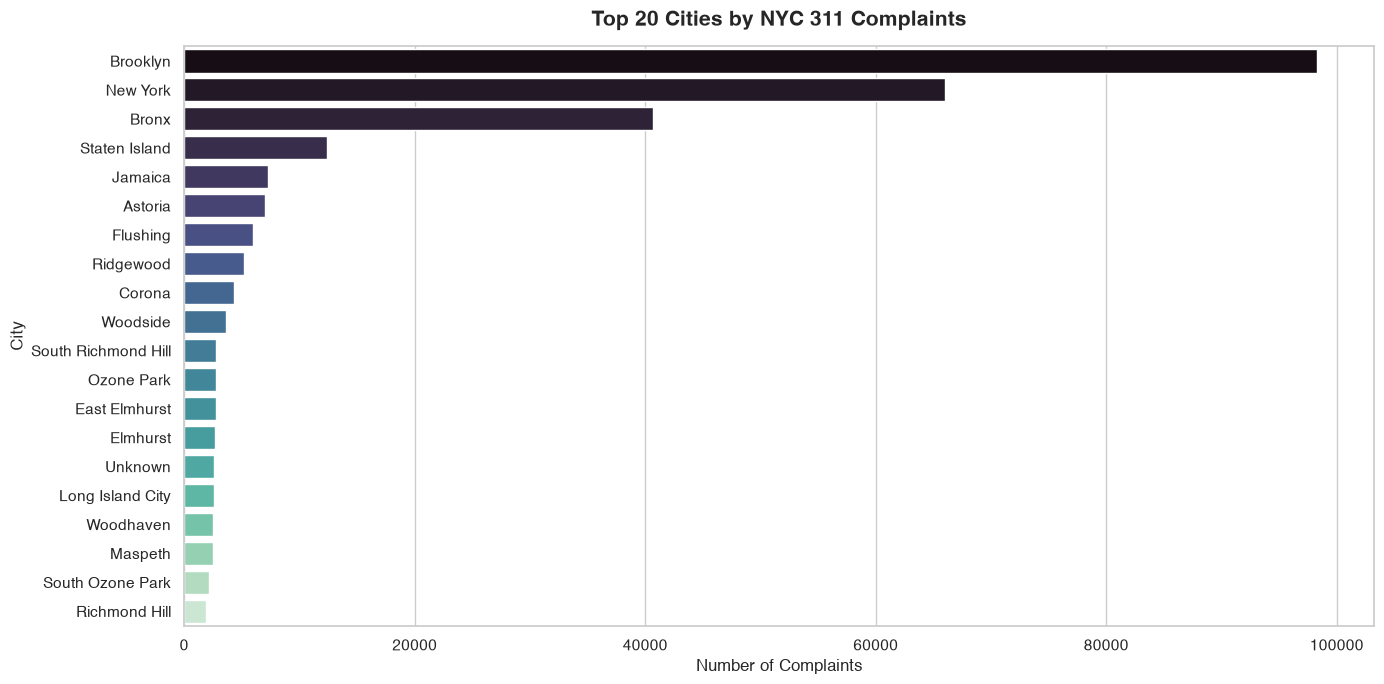

In [11]:
city_counts = df['City'].value_counts()
print("Top 15 Cities by Service Request Volume:")
print(city_counts.head(15))

plt.figure(figsize=(14, 7))
top_20_cities = city_counts.head(20)
sns.barplot(x=top_20_cities.values, y=top_20_cities.index, palette='mako')
plt.title("Top 20 Cities by NYC 311 Complaints", fontsize=15, fontweight='bold', pad=15)
plt.xlabel("Number of Complaints", fontsize=12)
plt.ylabel("City", fontsize=12)
plt.tight_layout()
plt.savefig('../visualizations/city_complaints.png', dpi=300)
plt.show()


## 7. Complaint Concentration Across Brooklyn
Filter geocoded service requests located in Brooklyn to visualize spatial clustering.

In [12]:
brooklyn_df = df[
    (df['Borough'].str.upper() == 'BROOKLYN') &
    (df['Latitude'].notnull()) &
    (df['Longitude'].notnull())
].copy()

print(f"Total geocoded complaints in Brooklyn: {len(brooklyn_df):,}")


Total geocoded complaints in Brooklyn: 98,113


### 7.1 Brooklyn Scatter Plot

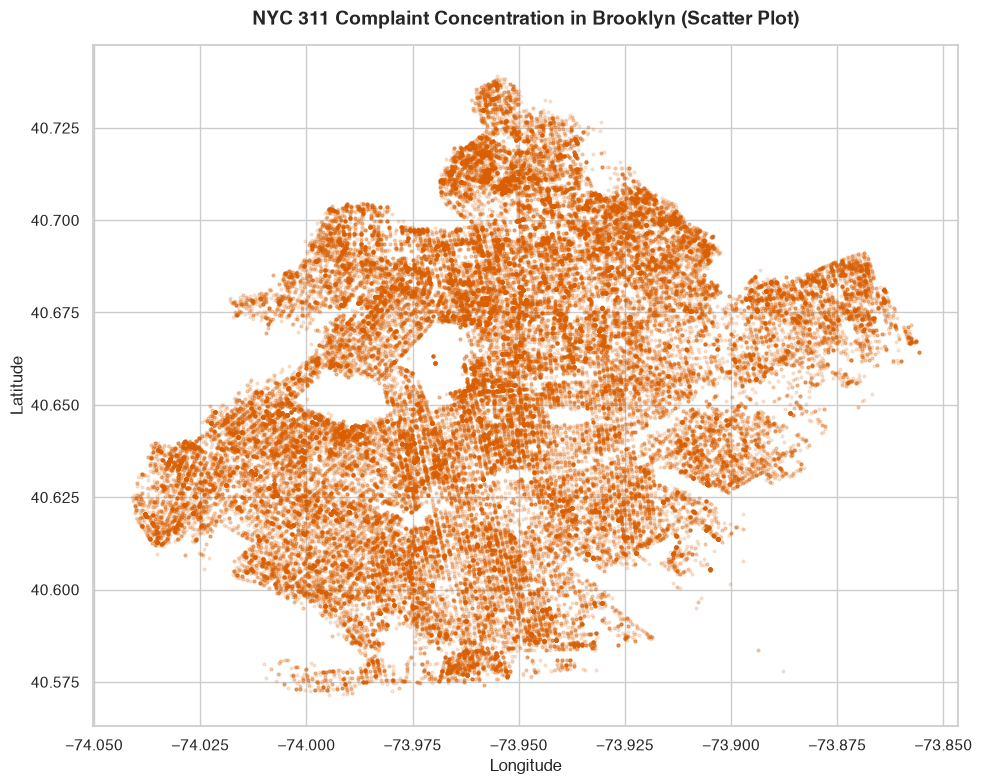

In [13]:
plt.figure(figsize=(10, 8))
plt.scatter(brooklyn_df['Longitude'], brooklyn_df['Latitude'], alpha=0.15, s=4, color='#d95f02')
plt.title("NYC 311 Complaint Concentration in Brooklyn (Scatter Plot)", fontsize=14, fontweight='bold', pad=15)
plt.xlabel("Longitude", fontsize=12)
plt.ylabel("Latitude", fontsize=12)
plt.tight_layout()
plt.savefig('../visualizations/brooklyn_scatter.png', dpi=300)
plt.show()


### 7.2 Brooklyn Hexbin Density Plot

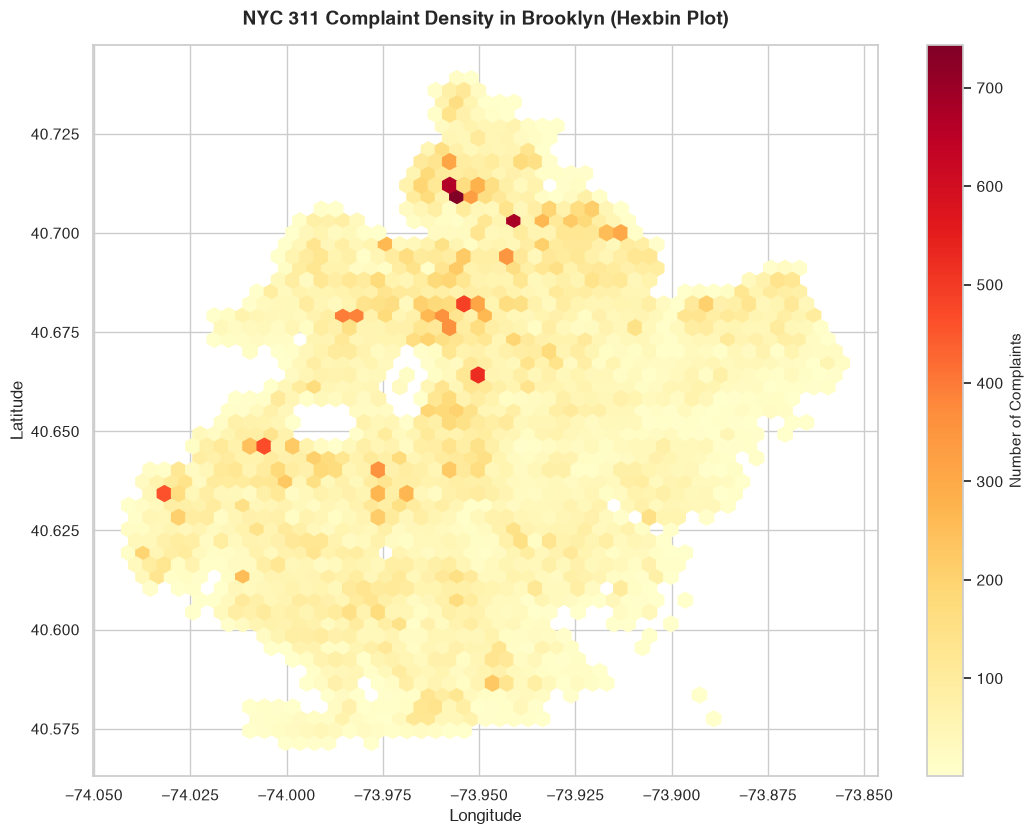

In [14]:
plt.figure(figsize=(11, 8.5))
hb = plt.hexbin(
    brooklyn_df['Longitude'], 
    brooklyn_df['Latitude'], 
    gridsize=50, 
    cmap='YlOrRd', 
    mincnt=1
)
cb = plt.colorbar(hb)
cb.set_label('Number of Complaints', fontsize=11)
plt.title("NYC 311 Complaint Density in Brooklyn (Hexbin Plot)", fontsize=14, fontweight='bold', pad=15)
plt.xlabel("Longitude", fontsize=12)
plt.ylabel("Latitude", fontsize=12)
plt.tight_layout()
plt.savefig('../visualizations/brooklyn_hexbin.png', dpi=300)
plt.show()


## 8. Find Major Types of Complaints

### 8.1 Count and Top 10 Complaint Types

In [15]:
complaint_counts = df['Complaint Type'].value_counts()
top_10_complaints = complaint_counts.head(10)

print("Top 10 NYC 311 Complaint Types:")
for idx, (c_type, count) in enumerate(top_10_complaints.items(), 1):
    pct = (count / len(df)) * 100
    print(f" {idx:2d}. {c_type:<32}: {count:>7,} ({pct:5.2f}%)")


Top 10 NYC 311 Complaint Types:
  1. Blocked Driveway                :  77,044 (25.62%)
  2. Illegal Parking                 :  75,361 (25.06%)
  3. Noise - Street/Sidewalk         :  48,612 (16.17%)
  4. Noise - Commercial              :  35,577 (11.83%)
  5. Derelict Vehicle                :  17,718 ( 5.89%)
  6. Noise - Vehicle                 :  17,083 ( 5.68%)
  7. Animal Abuse                    :   7,778 ( 2.59%)
  8. Traffic                         :   4,498 ( 1.50%)
  9. Homeless Encampment             :   4,416 ( 1.47%)
 10. Noise - Park                    :   4,042 ( 1.34%)


### 8.2 Bar Graph: Top 10 Complaint Types

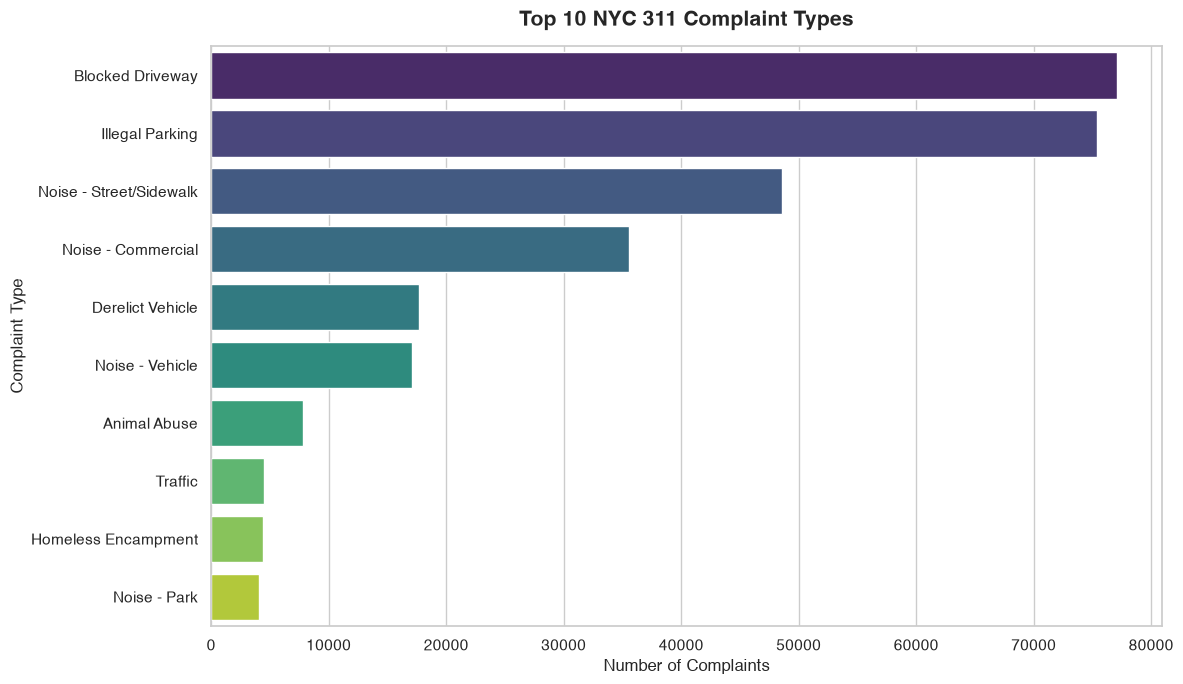

In [16]:
plt.figure(figsize=(12, 7))
sns.barplot(x=top_10_complaints.values, y=top_10_complaints.index, palette='viridis')
plt.title("Top 10 NYC 311 Complaint Types", fontsize=15, fontweight='bold', pad=15)
plt.xlabel("Number of Complaints", fontsize=12)
plt.ylabel("Complaint Type", fontsize=12)
plt.tight_layout()
plt.savefig('../visualizations/top_complaints.png', dpi=300)
plt.show()


### 8.3 Display Complaint Types in Each City in a Separate Dataset

In [17]:
city_complaint_dataset = pd.crosstab(df['City'], df['Complaint Type'])
city_complaint_dataset.to_csv('../output/complaint_types_by_city.csv')
print(f"Dataset saved to '../output/complaint_types_by_city.csv'. Dimensions: {city_complaint_dataset.shape}")
city_complaint_dataset.head(10)


Dataset saved to '../output/complaint_types_by_city.csv'. Dimensions: (49, 24)


Complaint Type,Agency Issues,Animal Abuse,Animal in a Park,Bike/Roller/Skate Chronic,Blocked Driveway,Derelict Vehicle,Disorderly Youth,Drinking,Ferry Complaint,Graffiti,...,Noise - House of Worship,Noise - Park,Noise - Street/Sidewalk,Noise - Vehicle,Panhandling,Posting Advertisement,Squeegee,Traffic,Urinating in Public,Vending
City,,,,,,,,,,,,,,,,,,,,,
Arverne,0,38,0,0,35,27,2,1,0,1,...,11,2,29,7,1,0,0,0,1,1
Astoria,0,125,0,15,2734,363,3,35,0,4,...,19,61,500,204,1,1,0,47,9,54
Bayside,0,37,0,0,377,198,1,1,0,3,...,2,4,15,16,0,0,0,9,0,2
Bellerose,0,7,0,1,95,89,2,1,0,0,...,1,1,13,10,1,1,0,7,1,0
Breezy Point,0,2,0,0,3,3,0,1,0,0,...,0,0,1,1,0,0,0,0,0,0
Bronx,0,1415,0,20,12755,1953,63,188,0,9,...,79,547,8892,3396,19,17,0,355,51,379
Brooklyn,0,2394,0,111,28148,5181,72,257,0,43,...,340,1555,13356,5177,49,45,0,1085,136,515
Cambria Heights,0,11,0,0,147,115,0,0,0,0,...,2,0,25,77,0,0,0,6,0,0
Central Park,0,0,0,0,0,0,0,0,0,0,...,0,0,95,0,0,0,0,0,0,0


## 9. Visualize Major Types of Complaints in Each City
Heatmap displaying top 10 complaint types across the 15 cities with highest activity.

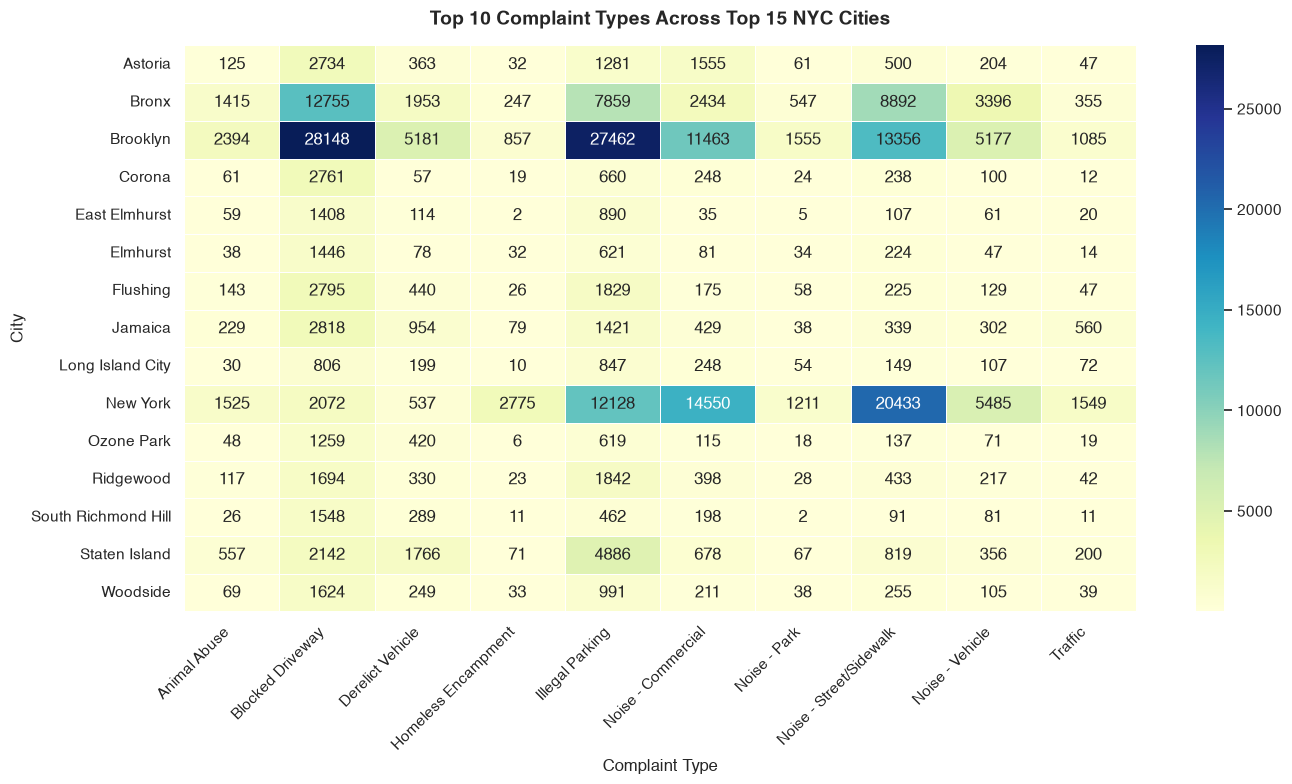

In [18]:
top_10_types = top_10_complaints.index.tolist()
top_15_cities = df[df['City'] != 'Unknown']['City'].value_counts().head(15).index.tolist()

city_comp_sub = df[
    (df['Complaint Type'].isin(top_10_types)) &
    (df['City'].isin(top_15_cities))
]
city_comp_matrix = pd.crosstab(city_comp_sub['City'], city_comp_sub['Complaint Type'])

plt.figure(figsize=(14, 8))
sns.heatmap(city_comp_matrix, cmap='YlGnBu', annot=True, fmt='d', linewidths=0.5)
plt.title("Top 10 Complaint Types Across Top 15 NYC Cities", fontsize=14, fontweight='bold', pad=15)
plt.xlabel("Complaint Type", fontsize=12)
plt.ylabel("City", fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.savefig('../visualizations/city_top_complaints_heatmap.png', dpi=300)
plt.show()


## 10. Average & Median Response Time Analysis

Response time is calculated as:
$$\text{Response Time (Hours)} = \frac{\text{Closed Date} - \text{Created Date}}{3600\text{ seconds}}$$

We exclude open cases and invalid negative durations.

In [19]:
df['Response_Time_Hours'] = (df['Closed Date'] - df['Created Date']).dt.total_seconds() / 3600.0

response_df = df[df['Response_Time_Hours'].notnull() & (df['Response_Time_Hours'] > 0)].copy()
print(f"Total resolved complaints analyzed: {len(response_df):,}")

avg_response = response_df.groupby('Complaint Type')['Response_Time_Hours'].mean().sort_values(ascending=False)
median_response = response_df.groupby('Complaint Type')['Response_Time_Hours'].median().sort_values(ascending=False)
counts = response_df.groupby('Complaint Type')['Response_Time_Hours'].count()

response_summary = pd.DataFrame({
    'Resolved_Count': counts,
    'Mean_Response_Hours': avg_response,
    'Median_Response_Hours': median_response
}).loc[avg_response.index]

response_summary.head(15)


Total resolved complaints analyzed: 298,534


,Resolved_Count,Mean_Response_Hours,Median_Response_Hours
Complaint Type,,,
Animal in a Park,1,336.834722,336.834722
Derelict Vehicle,17588,7.364140,4.116667
Graffiti,113,7.151251,4.533333
Agency Issues,6,5.260324,4.904722
Animal Abuse,7768,5.213244,3.300000
Blocked Driveway,76810,4.740905,3.166667
Illegal Parking,74532,4.501152,2.933333
Panhandling,305,4.372768,2.666667
Homeless Encampment,4416,4.365570,2.850000


### 10.1 Average Resolution Time for Top 20 Most Frequent Complaints

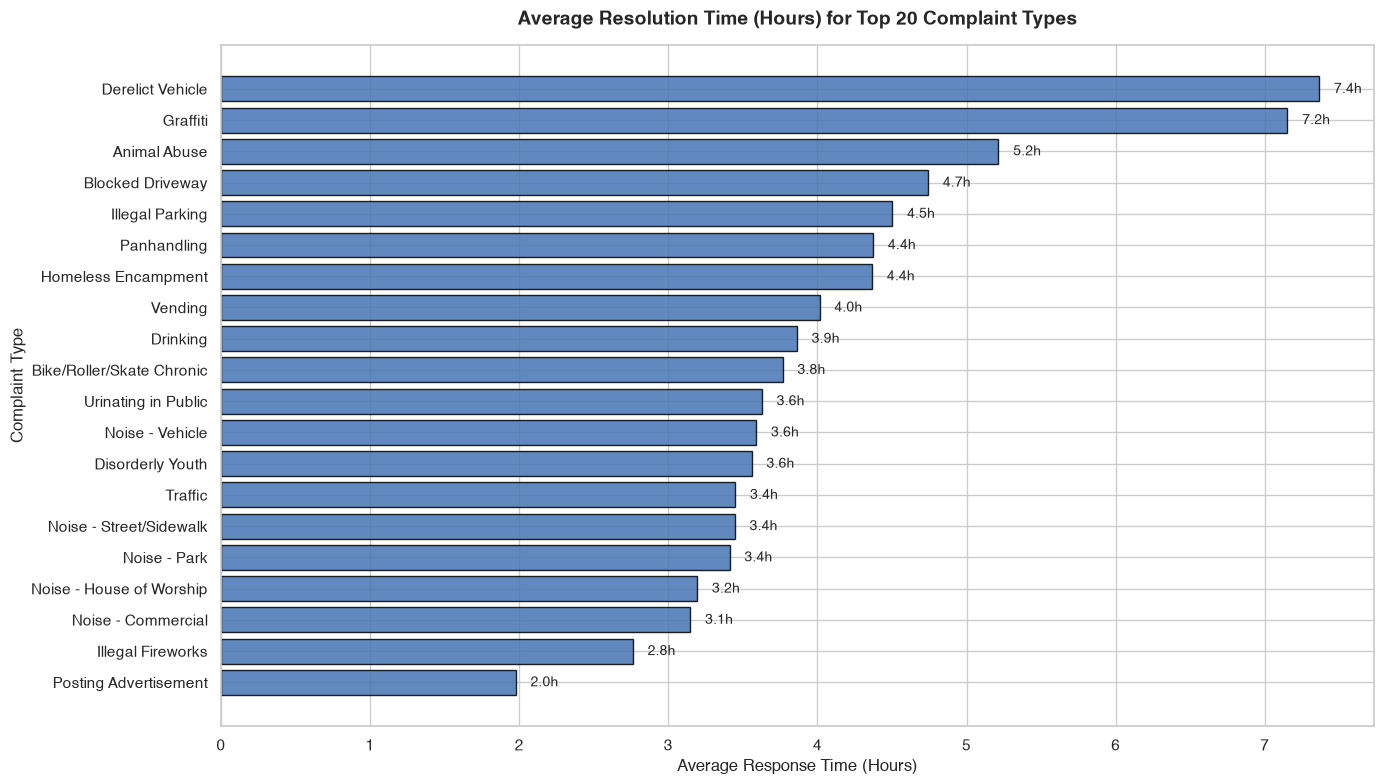

In [20]:
top_20_vol_types = response_df['Complaint Type'].value_counts().head(20).index
top_20_avg = avg_response.loc[top_20_vol_types].sort_values(ascending=True)

plt.figure(figsize=(14, 8))
bars = plt.barh(top_20_avg.index, top_20_avg.values, color='#4575b4', edgecolor='black', alpha=0.85)
plt.title("Average Resolution Time (Hours) for Top 20 Complaint Types", fontsize=14, fontweight='bold', pad=15)
plt.xlabel("Average Response Time (Hours)", fontsize=12)
plt.ylabel("Complaint Type", fontsize=12)

for bar in bars:
    w = bar.get_width()
    plt.text(w + 0.1, bar.get_y() + bar.get_height()/2, f"{w:.1f}h", ha='left', va='center', fontsize=10)

plt.tight_layout()
plt.savefig('../visualizations/response_time.png', dpi=300)
plt.show()


## 11. Statistical Hypothesis Testing – Chi-Square Test of Independence

We investigate whether the distribution of complaint types depends on the Borough.

### Hypotheses:
- **Null Hypothesis ($H_0$):** Complaint Type and Borough are **independent** (the distribution of complaint types is identical across boroughs).
- **Alternative Hypothesis ($H_1$):** Complaint Type and Borough are **dependent / associated** (the distribution of complaint types differs significantly by borough).
- **Significance Level ($\alpha$):** 0.05

### Chi-Square Test Statistic:
$$\chi^2 = \sum \frac{(O_{ij} - E_{ij})^2}{E_{ij}}$$


In [21]:
valid_boroughs = ['Manhattan', 'Brooklyn', 'Queens', 'Bronx', 'Staten Island']
stat_df = df[
    (df['Complaint Type'].isin(top_10_types)) &
    (df['Borough'].isin(valid_boroughs))
]

contingency_table = pd.crosstab(stat_df['Borough'], stat_df['Complaint Type'])
print("Contingency Table (Borough vs Top 10 Complaint Types):")
contingency_table


Contingency Table (Borough vs Top 10 Complaint Types):


Complaint Type,Animal Abuse,Blocked Driveway,Derelict Vehicle,Homeless Encampment,Illegal Parking,Noise - Commercial,Noise - Park,Noise - Street/Sidewalk,Noise - Vehicle,Traffic
Borough,,,,,,,,,,
Bronx,1415,12755,1953,246,7859,2434,547,8891,3396,357
Brooklyn,2394,28148,5181,857,27462,11463,1555,13355,5177,1086
Manhattan,1525,2073,537,2778,12132,14560,1211,20550,5485,1551
Queens,1876,31644,8110,464,21982,6075,636,4407,2615,1305
Staten Island,557,2142,1766,71,4886,679,67,820,356,198


### 11.1 Execute Chi-Square Test and Compute p-value

In [22]:
chi2, p_val, dof, expected = chi2_contingency(contingency_table)

print(f"Chi-Square Statistic (chi2) : {chi2:,.4f}")
print(f"P-Value                     : {p_val}")
print(f"Degrees of Freedom (dof)    : {dof}")

alpha = 0.05
if p_val < alpha:
    print(f"\nConclusion: Reject the Null Hypothesis H0 (p-value {p_val:.3e} < {alpha}).")
    print("There is highly statistically significant evidence that Complaint Type and Borough are ASSOCIATED.")
else:
    print(f"\nConclusion: Fail to reject the Null Hypothesis H0 (p-value {p_val:.4f} >= {alpha}).")
    print("Insufficient evidence of association.")


Chi-Square Statistic (chi2) : 64,425.3089
P-Value                     : 0.0
Degrees of Freedom (dof)    : 36

Conclusion: Reject the Null Hypothesis H0 (p-value 0.000e+00 < 0.05).
There is highly statistically significant evidence that Complaint Type and Borough are ASSOCIATED.


## 12. Key Findings & Project Conclusions

1. **Dataset Overview**:
   - Total records: **300,698**; Features: **53**.
   - Missing data predominantly concentrated in agency-specific or transit attributes (`School or Citywide Complaint`, `Vehicle Type`, `Ferry Direction`).
2. **Temporal Trends**:
   - Volume peaks during warmer summer months (May–August), driven by elevated noise and street complaints.
3. **Geographic Distribution**:
   - **Brooklyn** accounted for the largest volume of complaints (**98,307**), followed by **New York (Manhattan)** (**65,994**) and **Bronx** (**40,702**).
   - In Brooklyn, complaints are concentrated in northern and central neighborhoods (Crown Heights, Bedford-Stuyvesant, Bushwick, Flatbush).
4. **Dominant Complaint Types**:
   - **Blocked Driveway** (77,044 / 25.6%) and **Illegal Parking** (75,361 / 25.1%) constitute over **50.6%** of all 311 calls.
   - Noise-related categories (`Street/Sidewalk`, `Commercial`, `Vehicle`, `Park`) cumulatively represent over **35%** of requests.
5. **Response Times**:
   - Noise and traffic complaints are resolved fastest (median ~2 hours).
   - `Derelict Vehicle` (mean ~7.36 hours) and `Animal Abuse` (mean ~5.21 hours) exhibit longer resolution times.
6. **Statistical Significance**:
   - Chi-Square test yields $\chi^2 = 64,425.31$ ($p < 10^{-16}$, $dof=36$), strongly rejecting independence. Borough location directly influences the types of complaints logged (e.g., Blocked Driveway in Queens/Brooklyn vs. Noise - Commercial in Manhattan).
